# Homework 1 – Daily electricity demand in Spain

## 1. Dataset

The series is the total **daily electricity demand in Spain**, in GWh, from **Red Eléctrica de España (REE)**, the national transmission system operator, downloaded through its public REData API. The frequency is **daily**, covering 1 Jan 2019 – 31 Dec 2025 (**2,557 observations, 7 years**), with no missing values.

As an additional variable, the daily mean temperature from the **Open-Meteo** Historical API is used: a population-weighted average of five large cities (Madrid, Barcelona, Valencia, Seville, Bilbao).

### Setup: imports, MLflow, data and helper functions

In [7]:
import numpy as np
import pandas as pd
import plotly
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import mlflow
from pathlib import Path
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL

print("plotly", plotly.__version__, "| mlflow", mlflow.__version__)

plotly 7.1.0 | mlflow 3.18.0


In [8]:
import mlflow
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("hw1-222133")  

<Experiment: artifact_location='mlflow-artifacts:/2', creation_time=1794022283246, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1794188133654, lifecycle_stage='active', name='hw1-222133', tags={}, trace_location=None, workspace='default'>

In [9]:
data = pd.read_csv(Path("../data/processed/spain_daily.csv"), index_col=0, parse_dates=True).asfreq("D")
y = data["load_gwh"]
t = data["temp_c"]
print(data.shape, data.index.min().date(), data.index.max().date())

(2557, 2) 2019-01-01 2025-12-31


In [10]:
MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
WEEKDAYS = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

def plot_lines(original, smoothed, title, ytitle="GWh"):
    fig = go.Figure()
    fig.add_scatter(x=original.index, y=original, name="original", line=dict(color="lightgrey", width=1))
    for label, s in smoothed.items():
        fig.add_scatter(x=s.index, y=s, name=label)
    fig.update_layout(title=title, xaxis_title="Date", yaxis_title=ytitle, hovermode="x unified")
    return fig

def plot_decomposition(res, title):
    parts = {"observed": res.observed, "trend": res.trend}
    if isinstance(res.seasonal, pd.DataFrame):
        parts.update({c: res.seasonal[c] for c in res.seasonal.columns})
    else:
        parts["seasonal"] = res.seasonal
    parts["remainder"] = res.resid
    fig = make_subplots(rows=len(parts), cols=1, shared_xaxes=True,
                        vertical_spacing=0.04, subplot_titles=list(parts))
    for i, (name, s) in enumerate(parts.items(), start=1):
        fig.add_scatter(x=s.index, y=s, row=i, col=1, marker=dict(size=3),
                        mode="markers" if name == "remainder" else "lines")
    fig.update_layout(title=title, height=180 * len(parts), showlegend=False)
    return fig

def strength(comp, resid):
    df = pd.concat([comp, resid], axis=1).dropna()
    return max(0, 1 - df.iloc[:, 1].var() / (df.iloc[:, 0] + df.iloc[:, 1]).var())

def log_run(name, technique, params, metrics, fig, fname):
    with mlflow.start_run(run_name=name):
        mlflow.set_tag("technique", technique)
        for k, v in params.items():
            mlflow.log_param(k, v)
        for k, v in metrics.items():
            mlflow.log_metric(k, float(v))
        mlflow.log_figure(fig, fname)
    print(name, {k: round(float(v), 3) for k, v in metrics.items()})
    fig.show()

## 2. Visualization

In [11]:
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"

pio.templates["course"] = go.layout.Template(layout=dict(
    colorway=["#0b7a43", "#2b6cb0", "#c8a400", "#d1495b", "#6b4c9a"],
    height=450,
    font=dict(family="Inter, Arial", size=13),
    margin=dict(l=60, r=30, t=70, b=50),
    title=dict(x=0.02, font=dict(size=17)),
    hoverlabel=dict(font_size=12),
))
pio.templates.default = "plotly_white+course"

MONTHS = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
DAYS = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
SEASON_ORDER = ["Winter","Spring","Summer","Autumn"]
SEASONS = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
           6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
LABELS = {"load_gwh": "Demand (GWh)", "temp_c": "Temperature (°C)",
          "month": "Month", "weekday": "Day", "season": "Season", "date": "Date"}

In [12]:
SEASONS = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
           6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
v = data.assign(month=data.index.month.map(dict(enumerate(MONTHS, 1))),
                weekday=data.index.dayofweek.map(dict(enumerate(DAYS))),
                season=data.index.month.map(SEASONS),
                year=data.index.year)
figs = {}

# Q1 – line with range slider and buttons
f = px.line(data, y="load_gwh", labels=LABELS,
            title="Q1: How does daily electricity demand change over time?")
f.update_traces(line=dict(width=1))
f.update_xaxes(title="Date", rangeslider_visible=True,
               rangeselector=dict(buttons=[dict(count=3, label="3M", step="month", stepmode="backward"),
                                           dict(count=1, label="1Y", step="year", stepmode="backward"),
                                           dict(step="all", label="All")]))
figs["q1_line.html"] = f

# Q2 – by month, coloured by season
figs["q2_month_box.html"] = px.box(v, x="month", y="load_gwh", color="season", points="outliers",
    category_orders={"month": MONTHS, "season": SEASON_ORDER},
    labels=LABELS, title="Q2: Which months have the highest demand?")

# Q3 – by day of the week
figs["q3_weekday_box.html"] = px.box(v, x="weekday", y="load_gwh", points="outliers",
    category_orders={"weekday": DAYS}, labels=LABELS,
    title="Q3: How much lower is demand on weekends?")

# Q4 – temperature vs demand, coloured by season, one overall LOWESS line
figs["q4_temp_scatter.html"] = px.scatter(v, x="temp_c", y="load_gwh", color="season", opacity=0.45,
    trendline="lowess", trendline_scope="overall", trendline_color_override="black",
    category_orders={"season": SEASON_ORDER},
    labels=LABELS, title="Q4: How does temperature affect demand?")

# Q5 – heatmap year × month
table = v.groupby(["year", v.index.month])["load_gwh"].mean().unstack()
figs["q5_heatmap.html"] = px.imshow(table, x=MONTHS, y=table.index.astype(str), text_auto=".0f",
    aspect="auto", color_continuous_scale="YlOrRd",
    labels=dict(x="Month", y="Year", color="GWh"),
    title="Q5: Average daily demand by month and year (GWh)")

with mlflow.start_run(run_name="visualization"):
    mlflow.set_tag("technique", "EDA")
    for name, f in figs.items():
        mlflow.log_figure(f, name)
        f.show()



🏃 View run visualization at: http://127.0.0.1:5000/#/experiments/2/runs/c3e67e0e3abf40b7b156fe2ee3f6137a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


**Q1 – Line chart with range slider:** overview of the whole series. A dense weekly zig-zag, yearly waves with two peaks (winter and summer), a sharp drop in March–April 2020 (COVID lockdown) and single very low days (holidays, the 28 April 2025 blackout).

**Q2 – Box plot by month:** checks for yearly seasonality. Demand is highest in winter (Dec–Feb, heating) and summer (Jul–Aug, cooling) and lowest in spring and autumn, so the yearly season has two peaks.

**Q3 – Box plot by weekday:** checks for weekly seasonality. Monday–Friday are similar, Saturday is lower and Sunday is the lowest, which supports m = 7.

**Q4 – Temperature vs demand (LOWESS line):** the relationship is U-shaped: demand rises when it is cold (heating) and when it is hot (cooling), and is lowest at mild temperatures. This explains the two yearly peaks.

**Q5 – Heatmap year × month:** compares all months of all years at once. The winter/summer pattern repeats every year, and April 2020 stands out as unusually low.

## 3. Smoothing

### 3.1 SMA – three windows (7, 30, 365)

In [13]:
for w in [7, 30, 365]:
    sm = y.rolling(w).mean(); r = (y - sm).dropna()
    log_run(f"SMA_w{w}", "SMA", {"window": w}, {"sse": (r**2).sum(), "resid_std": r.std()},
            plot_lines(y, {f"SMA {w}": sm}, f"SMA, window = {w}"), f"sma_{w}.html")

🏃 View run SMA_w7 at: http://127.0.0.1:5000/#/experiments/2/runs/4960dacdc01b419e84d44ed5b0092c25
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
SMA_w7 {'sse': 6615900.263, 'resid_std': 50.936}


🏃 View run SMA_w30 at: http://127.0.0.1:5000/#/experiments/2/runs/3d8dc21f2c2f411b9cea4414261ff25f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
SMA_w30 {'sse': 8577863.307, 'resid_std': 58.26}


🏃 View run SMA_w365 at: http://127.0.0.1:5000/#/experiments/2/runs/e7f2db51168742f691900539a736babe
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
SMA_w365 {'sse': 10896268.493, 'resid_std': 70.491}


A window of 7 removes the weekly zig-zag, 30 smooths short-term noise but keeps the yearly waves, and 365 leaves only the long-term trend. A larger window gives a smoother line but more lag, so SSE and the residual std (printed above) grow with the window.

### 3.2 WMA (window 7)

In [14]:
wts = np.arange(1, 8)
wma = y.rolling(7).apply(lambda x: np.dot(x, wts) / wts.sum(), raw=True); r = (y - wma).dropna()
log_run("WMA_w7", "WMA", {"window": 7}, {"sse": (r**2).sum(), "resid_std": r.std()},
        plot_lines(y, {"WMA 7": wma, "SMA 7": y.rolling(7).mean()}, "WMA vs SMA, window 7"), "wma_7.html")

🏃 View run WMA_w7 at: http://127.0.0.1:5000/#/experiments/2/runs/87d1a005ba2e4a71b4336faf9e2a1b4c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
WMA_w7 {'sse': 5122957.394, 'resid_std': 44.822}


WMA gives more weight to recent days, so it reacts faster than SMA with the same window (e.g. the April 2020 drop) and has less lag, at the cost of slightly less smoothing.

### 3.3 SES – three values of α (0.1, 0.3, 0.7)

In [15]:
for a in [0.1, 0.3, 0.7]:
    fit = SimpleExpSmoothing(y, initialization_method="estimated").fit(smoothing_level=a, optimized=False)
    log_run(f"SES_a{a}", "SES", {"alpha": a}, {"aic": fit.aic, "sse": fit.sse, "resid_std": fit.resid.std()},
            plot_lines(y, {f"SES α={a}": fit.fittedvalues}, f"SES, α = {a}"), f"ses_{a}.html")

🏃 View run SES_a0.1 at: http://127.0.0.1:5000/#/experiments/2/runs/859ab304ec124dc1a256b586b034f17a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
SES_a0.1 {'aic': 20736.993, 'sse': 8494396.824, 'resid_std': 57.648}


🏃 View run SES_a0.3 at: http://127.0.0.1:5000/#/experiments/2/runs/23bfcfa8f85d4ce3a316f6bb7fd4684f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
SES_a0.3 {'aic': 20627.059, 'sse': 8136933.424, 'resid_std': 56.422}


🏃 View run SES_a0.7 at: http://127.0.0.1:5000/#/experiments/2/runs/115c11d13a3a418b988f311095001fa6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
SES_a0.7 {'aic': 20597.775, 'sse': 8044275.535, 'resid_std': 56.1}


A small α (0.1) gives a smooth, lagging line; a large α (0.7) follows the data and its noise closely. SES has no trend or seasonal component, so it cannot capture the weekly pattern, which is why Holt-Winters is used next.

### 3.4 Holt-Winters – additive vs multiplicative season (AIC)

In [16]:
for seas in ["add", "mul"]:
    hw = ExponentialSmoothing(y, trend="add", seasonal=seas, seasonal_periods=7,
                              initialization_method="estimated").fit()
    p = hw.params
    log_run(f"HW_{seas}", "Holt-Winters",
            {"seasonal": seas, "period": 7, "alpha": round(p["smoothing_level"], 4),
             "beta": round(p["smoothing_trend"], 4), "gamma": round(p["smoothing_seasonal"], 4)},
            {"aic": hw.aic, "sse": hw.sse, "resid_std": hw.resid.std()},
            plot_lines(y, {f"HW {seas}": hw.fittedvalues}, f"Holt-Winters ({seas}), m = 7"), f"hw_{seas}.html")
    print(seas, "AIC =", round(hw.aic, 1))

🏃 View run HW_add at: http://127.0.0.1:5000/#/experiments/2/runs/fae3a5324dfa4cdba4d9b718050a0338
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
HW_add {'aic': 16348.349, 'sse': 1515949.356, 'resid_std': 24.354}


add AIC = 16348.3
🏃 View run HW_mul at: http://127.0.0.1:5000/#/experiments/2/runs/e06fbeeb2f6048dba879f4d3b975e354
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
HW_mul {'aic': 16255.514, 'sse': 1461898.25, 'resid_std': 23.907}


mul AIC = 16255.5


Additive AIC = **16348.3**, multiplicative AIC = **16255.5**. The **multiplicative season fits better** (lower AIC): the weekend drop behaves like a percentage of the demand level, so it is larger in GWh when demand is high (winter, summer).

### 3.5 LOWESS – three values of frac (0.01, 0.05, 0.2)

In [17]:
x = np.arange(len(y))
for fr in [0.01, 0.05, 0.2]:
    sm = pd.Series(lowess(y.values, x, frac=fr, return_sorted=False), index=y.index); r = y - sm
    log_run(f"LOWESS_f{fr}", "LOWESS", {"frac": fr}, {"sse": (r**2).sum(), "resid_std": r.std()},
            plot_lines(y, {f"LOWESS frac={fr}": sm}, f"LOWESS, frac = {fr}"), f"lowess_{fr}.html")

🏃 View run LOWESS_f0.01 at: http://127.0.0.1:5000/#/experiments/2/runs/aec13a6e6f8341c38493922cb0067338
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
LOWESS_f0.01 {'sse': 6442605.385, 'resid_std': 49.82}


🏃 View run LOWESS_f0.05 at: http://127.0.0.1:5000/#/experiments/2/runs/3c7e1dce867d42fab5b0fcb62a8a5313
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
LOWESS_f0.05 {'sse': 8584749.358, 'resid_std': 57.78}


🏃 View run LOWESS_f0.2 at: http://127.0.0.1:5000/#/experiments/2/runs/2594897a19b64c9b9f6c81a6fe278041
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
LOWESS_f0.2 {'sse': 12120755.77, 'resid_std': 68.83}


frac = 0.01 (≈ 26 days) follows monthly changes, 0.05 (≈ 128 days) partly smooths the yearly waves, and 0.2 (≈ 511 days) shows only the long-term trend, including the 2020 dip. LOWESS has no lag but uses future values, so it is only for exploring the data.

## 4. Decomposition

### 4.1 Classical decomposition (m = 7)

In [18]:
for model in ["additive", "multiplicative"]:
    res = seasonal_decompose(y, model=model, period=7)
    met = {"resid_std": res.resid.std()}
    if model == "additive":
        met |= {"trend_strength": strength(res.trend, res.resid),
                "seasonal_strength": strength(res.seasonal, res.resid)}
    log_run(f"Classical_{model}", "Classical", {"model": model, "period": 7}, met,
            plot_decomposition(res, f"Classical {model} decomposition, m = 7"), f"classical_{model}.html")

🏃 View run Classical_additive at: http://127.0.0.1:5000/#/experiments/2/runs/6e6b6a1512ae451fa704e25801cbdca3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
Classical_additive {'resid_std': 19.19, 'trend_strength': 0.881, 'seasonal_strength': 0.841}


🏃 View run Classical_multiplicative at: http://127.0.0.1:5000/#/experiments/2/runs/0a99492c540a4ba1b3f3960968846f82
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
Classical_multiplicative {'resid_std': 0.028}


m = 7 because the data is daily and demand follows the working week (Q3). The seasonal panel looks like a solid band because the same 7-day pattern repeats about 365 times (zoom in to see the weekly wave). The yearly cycle ends up in the trend, since m = 7 does not cover it. The additive and multiplicative versions look almost the same; only the units differ (GWh around 0 vs factors around 1).

### 4.2 STL (m = 7)

In [19]:
stl = STL(y, period=7, robust=True).fit()
log_run("STL_m7", "STL", {"period": 7, "robust": True},
        {"resid_std": stl.resid.std(), "trend_strength": strength(stl.trend, stl.resid),
         "seasonal_strength": strength(stl.seasonal, stl.resid)},
        plot_decomposition(stl, "STL, m = 7"), "stl.html")

🏃 View run STL_m7 at: http://127.0.0.1:5000/#/experiments/2/runs/43728d27fde5498cb3031d0e2044fafd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
STL_m7 {'resid_std': 26.729, 'trend_strength': 0.769, 'seasonal_strength': 0.73}


STL is robust to outliers, lets the season change over time and keeps the trend up to both ends of the series (no missing values). As in the classical version, the yearly cycle stays in the trend, which is why MSTL is needed.

### 4.3 MSTL (m = 7 and 365) and seasonally adjusted series

In [20]:
mstl = MSTL(y, periods=(7, 365)).fit()
adjusted = y - mstl.seasonal.sum(axis=1)
f1 = plot_decomposition(mstl, "MSTL, m = 7 and 365")
f2 = plot_lines(y, {"seasonally adjusted": adjusted}, "Seasonally adjusted series (MSTL)")

with mlflow.start_run(run_name="MSTL_7_365"):
    mlflow.set_tag("technique", "MSTL")
    mlflow.log_param("period", "7,365")
    mlflow.log_metric("resid_std", mstl.resid.std())
    mlflow.log_metric("trend_strength", strength(mstl.trend, mstl.resid))
    mlflow.log_metric("seasonal_strength_7", strength(mstl.seasonal["seasonal_7"], mstl.resid))
    mlflow.log_metric("seasonal_strength_365", strength(mstl.seasonal["seasonal_365"], mstl.resid))
    mlflow.log_figure(f1, "mstl.html")
    mlflow.log_figure(f2, "adjusted.html")
print({"trend_strength": round(strength(mstl.trend, mstl.resid), 3),
       "seasonal_strength_7": round(strength(mstl.seasonal["seasonal_7"], mstl.resid), 3),
       "seasonal_strength_365": round(strength(mstl.seasonal["seasonal_365"], mstl.resid), 3)})
f1.show(); f2.show()

🏃 View run MSTL_7_365 at: http://127.0.0.1:5000/#/experiments/2/runs/1ffea8f528334e3d8a813da256eeb7b2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
{'trend_strength': np.float64(0.343), 'seasonal_strength_7': np.float64(0.756), 'seasonal_strength_365': np.float64(0.761)}


MSTL separates the two seasons: `seasonal_7` is the weekly pattern and `seasonal_365` the yearly pattern with two peaks (winter and summer); the trend is now smooth and long-term. The strengths are printed above. The **seasonally adjusted series** (original minus both seasons) keeps only the trend and unusual events, such as spring 2020.

### 4.4 Residuals – the most unusual days

In [21]:
top = mstl.resid.abs().sort_values(ascending=False).head(10).index
mstl.resid.loc[top].round(1)

2025-04-28   -134.0
2020-04-10   -115.8
2020-04-09   -114.7
2023-04-07   -106.5
2022-04-15   -104.9
2020-04-08   -101.4
2024-04-28     92.6
2022-06-15     89.2
2021-01-08     88.4
2020-04-07    -88.4
Name: resid, dtype: float64

**Why m = 7 and 365:** the working week (Q3) and the yearly heating/cooling cycle (Q2, Q4); two seasons are the reason for MSTL. **Additive or multiplicative:** the Holt-Winters AIC favours the multiplicative season (16255.5 < 16348.3).

**Residuals:** most days are close to 0, so trend + two seasons explain normal demand well. The largest residuals match real events:
- **28 Apr 2025** – the Iberian blackout (the largest residual);
- **7–10 Apr 2020** – strictest COVID lockdown phase plus Holy Week;
- **15 Apr 2022, 7 Apr 2023** – Good Friday (national holiday);
- **8 Jan 2021** – Storm Filomena (extreme cold);
- **15 Jun 2022** – likely the June 2022 heatwave;
- **28 Apr 2024** – no clear explanation found.

What the model does not explain are holidays, crises and extreme weather.

### Overview of all runs (parameters and metrics)

In [22]:
runs = mlflow.search_runs(experiment_names=["hw1-222133"])
cols = [c for c in runs.columns if c.startswith(("params.", "metrics."))]
runs = runs.sort_values("start_time").drop_duplicates("tags.mlflow.runName", keep="last")
runs[["tags.mlflow.runName"] + cols].sort_values("tags.mlflow.runName")

,tags.mlflow.runName,metrics.seasonal_strength_365,metrics.resid_std,metrics.trend_strength,metrics.seasonal_strength_7,metrics.seasonal_strength,metrics.sse,metrics.aic,params.period,params.robust,params.model,params.frac,params.beta,params.gamma,params.alpha,params.seasonal,params.window
3,Classical_additive,NaN,19.189665,0.880915,NaN,0.840918,NaN,NaN,7,None,additive,None,None,None,None,None,None
2,Classical_multiplicative,NaN,0.027838,NaN,NaN,NaN,NaN,NaN,7,None,multiplicative,None,None,None,None,None,None
8,HW_add,NaN,24.353530,NaN,NaN,NaN,1.515949e+06,16348.349018,7,None,None,None,0.0,0.0,0.861,add,None
7,HW_mul,NaN,23.907108,NaN,NaN,NaN,1.461898e+06,16255.514274,7,None,None,None,0.0055,0.0,0.8782,mul,None
6,LOWESS_f0.01,NaN,49.820280,NaN,NaN,NaN,6.442605e+06,NaN,None,None,None,0.01,None,None,None,None,None
5,LOWESS_f0.05,NaN,57.779847,NaN,NaN,NaN,8.584749e+06,NaN,None,None,None,0.05,None,None,None,None,None
4,LOWESS_f0.2,NaN,68.829565,NaN,NaN,NaN,1.212076e+07,NaN,None,None,None,0.2,None,None,None,None,None
0,MSTL_7_365,0.761496,25.358240,0.342927,0.755627,NaN,NaN,NaN,"7,365",None,None,None,None,None,None,None,None
11,SES_a0.1,NaN,57.647735,NaN,NaN,NaN,8.494397e+06,20736.992987,None,None,None,None,None,None,0.1,None,None
10,SES_a0.3,NaN,56.422164,NaN,NaN,NaN,8.136933e+06,20627.058942,None,None,None,None,None,None,0.3,None,None


## 5. MLflow tracking

All experiments are tracked in the MLflow experiment **hw1-222133**. Each technique and each parameter value is a separate run, tagged with `technique`. Every run logs its parameters (`log_param`: window, α/β/γ, period, frac), metrics (`log_metric`: AIC, SSE, residual std, trend and seasonal strength) and its interactive chart (`log_figure` → `.html`).
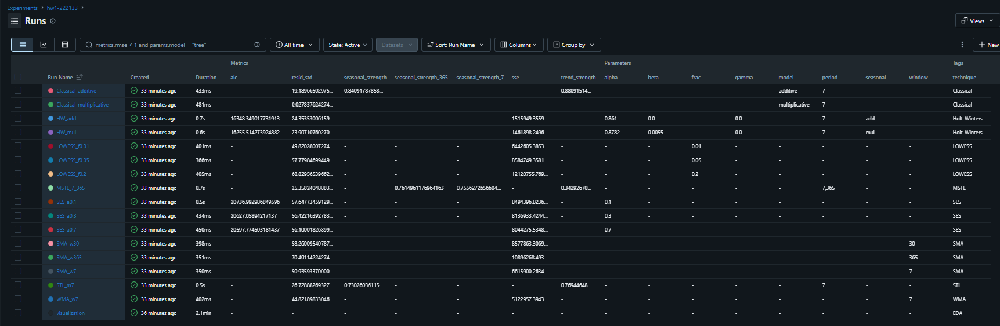

## Conclusion

**Main patterns.** Daily electricity demand in Spain (2019–2025) has **two clear seasons**: a weekly one (lower on Saturdays and lowest on Sundays) and a yearly one with two peaks, in winter (heating) and summer (cooling). This matches the U-shaped relationship between temperature and demand. The long-term trend is weak: once both seasons are separated with MSTL, the trend strength is only **0.34**, while the weekly (**0.76**) and yearly (**0.76**) seasons are about equally strong. Demand mostly repeats the same patterns rather than growing or falling over the years.

**Smoothing.** For all simple smoothers, more smoothing means a larger error: the SSE grows from 6.6 M to 8.6 M to 10.9 M for SMA windows of 7, 30 and 365 days, and from 6.4 M to 8.6 M to 12.1 M for LOWESS with frac 0.01, 0.05 and 0.2. WMA follows the data better than SMA with the same window (SSE 5.1 M vs 6.6 M). SES improves only slightly with a larger α (AIC 20737 → 20627 → 20598) because it has no seasonal component. Holt-Winters, which models the weekly season, is by far the best smoother: the residual std drops from about **56 GWh (SES) to about 24 GWh**.

**Additive vs multiplicative.** The multiplicative Holt-Winters model has a lower AIC (**16255.5 vs 16348.3**) and SSE (1.46 M vs 1.52 M), so the weekly season is **multiplicative**: the weekend drop scales with the demand level. The estimated γ = 0 means the weekly pattern is stable over the whole period.

**Decomposition.** With m = 7, classical decomposition and STL put the yearly cycle into the trend, which makes the trend look strong (0.88 and 0.77). MSTL with m = 7 and 365 separates the yearly season, so the trend strength drops to 0.34 and the residual std is lower than STL's (25.4 vs 26.7 GWh). For a daily series with two seasons, MSTL is therefore the right method.

**Residuals.** The largest residuals match real events: the strictest COVID lockdown phase in April 2020, Good Friday holidays (2022, 2023), Storm Filomena (January 2021), a likely heatwave in June 2022, and the Iberian blackout on 28 April 2025, the largest residual of all. What the model does not explain is mainly holidays, crises and extreme weather. One large residual (28 April 2024) has no clear explanation.

**Limitations.**
- Temperature is an approximation: a population-weighted average of five cities, not a national measure.
- Holidays are not modelled explicitly, so they appear as large residuals.
- STL and MSTL are additive, while Holt-Winters points to a multiplicative season; decomposing log(demand) would be more consistent.
- The data is daily, so the daily (hourly) cycle of demand is not visible.
- Smoothing methods such as centered averages and LOWESS use future values and are only suitable for exploring the data, not for forecasting.

**Next steps.**
- Use temperature (or heating and cooling degree days) and a Spanish holiday calendar as external variables in forecasting models (e.g. SARIMAX), and compare them with simple baselines such as SES and Holt-Winters.
- Compare Spain with Germany, where the yearly pattern is expected to have mainly a winter peak and a stronger weekly season.
- Separate the effect of tourism from temperature by analysing the Canary and Balearic Islands together with monthly tourist overnight stays (INE).